# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Exploratory Data Analysis  
- Load in the cleaned data

In [4]:
df = pd.read_csv('data/cleaned_aviation_data.csv', low_memory=False)

In [5]:
df.info

<bound method DataFrame.info of              Event.Id Investigation.Type Accident.Number  Event.Date  \
0      20001214X42095           Accident      SEA83LA036  1983-01-01   
1      20001214X42067           Accident      MKC83LA056  1983-01-01   
2      20001214X42063           Accident      MKC83LA050  1983-01-01   
3      20001214X42018           Accident      LAX83FUG11  1983-01-01   
4      20001214X41951           Accident      CHI83LA074  1983-01-01   
...               ...                ...             ...         ...   
67691  20221227106491           Accident      ERA23LA093  2022-12-26   
67692  20221227106494           Accident      ERA23LA095  2022-12-26   
67693  20221227106497           Accident      WPR23LA075  2022-12-26   
67694  20221227106498           Accident      WPR23LA076  2022-12-26   
67695  20221230106513           Accident      ERA23LA097  2022-12-29   

              Location        Country Latitude Longitude Airport.Code  \
0          NEWPORT, OR  United

In [6]:
df.shape

(67696, 33)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [7]:
small_aircraft = df[df['Total_on_board'] < 20]

large_aircraft = df[df['Total_on_board'] >= 20]

In [8]:
# Check sample counts for each group
print(f"Small aircraft incidents: {len(small_aircraft)}")
print(f"Large aircraft incidents: {len(large_aircraft)}")

Small aircraft incidents: 65125
Large aircraft incidents: 2571


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [15]:
import warnings
warnings.filterwarnings('ignore')

In [16]:
# Compute mean injury fraction per Make for small aircraft and take lowest 15
top15_small_makes = (
    small_aircraft.groupby('Make')['Severe_Injury_Fraction']
    .mean()
    .nsmallest(15)
    .reset_index()
)

In [17]:
# Compute mean injury fraction per Make for large aircraft and take lowest 15
top15_large_makes = (
    large_aircraft.groupby('Make')['Severe_Injury_Fraction']
    .mean()
    .nsmallest(15)
    .reset_index()
)

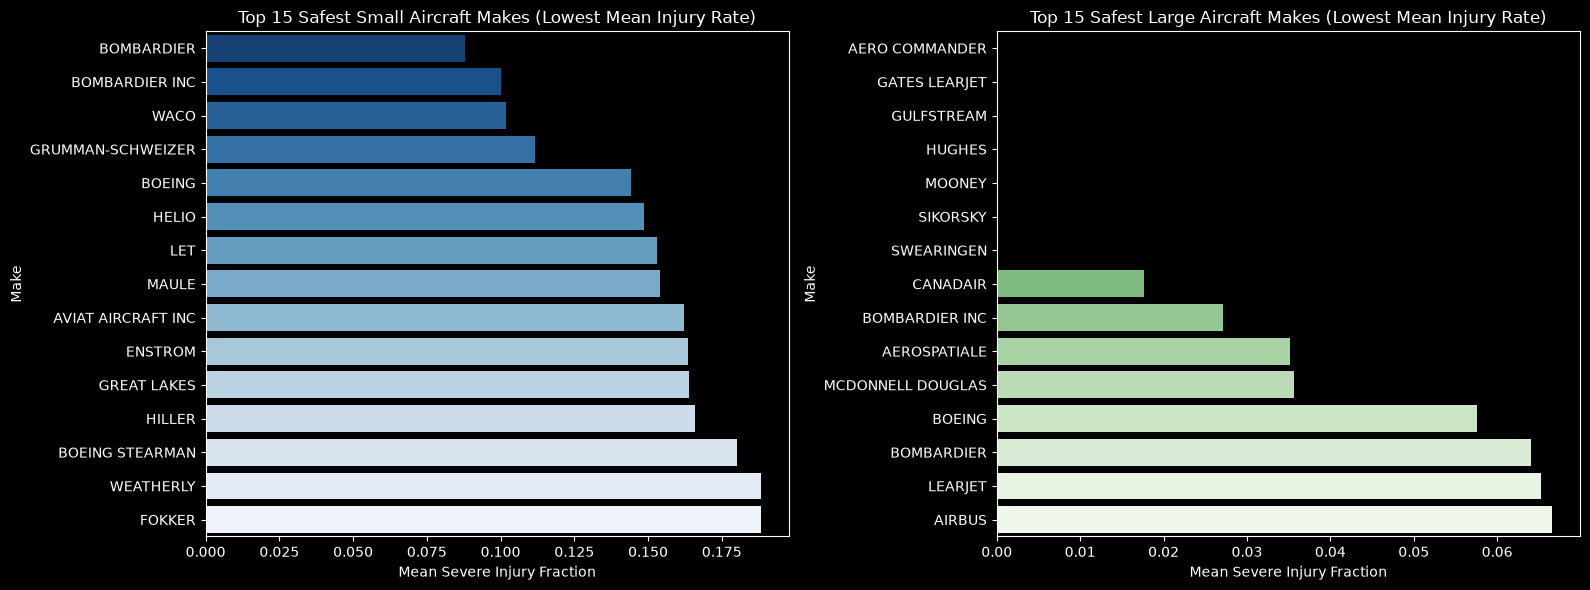

In [18]:
# Create a side-by-side subplot comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top15_small_makes, x='Severe_Injury_Fraction', y='Make', ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 15 Safest Small Aircraft Makes (Lowest Mean Injury Rate)')
axes[0].set_xlabel('Mean Severe Injury Fraction')

sns.barplot(data=top15_large_makes, x='Severe_Injury_Fraction', y='Make', ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 15 Safest Large Aircraft Makes (Lowest Mean Injury Rate)')
axes[1].set_xlabel('Mean Severe Injury Fraction')

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

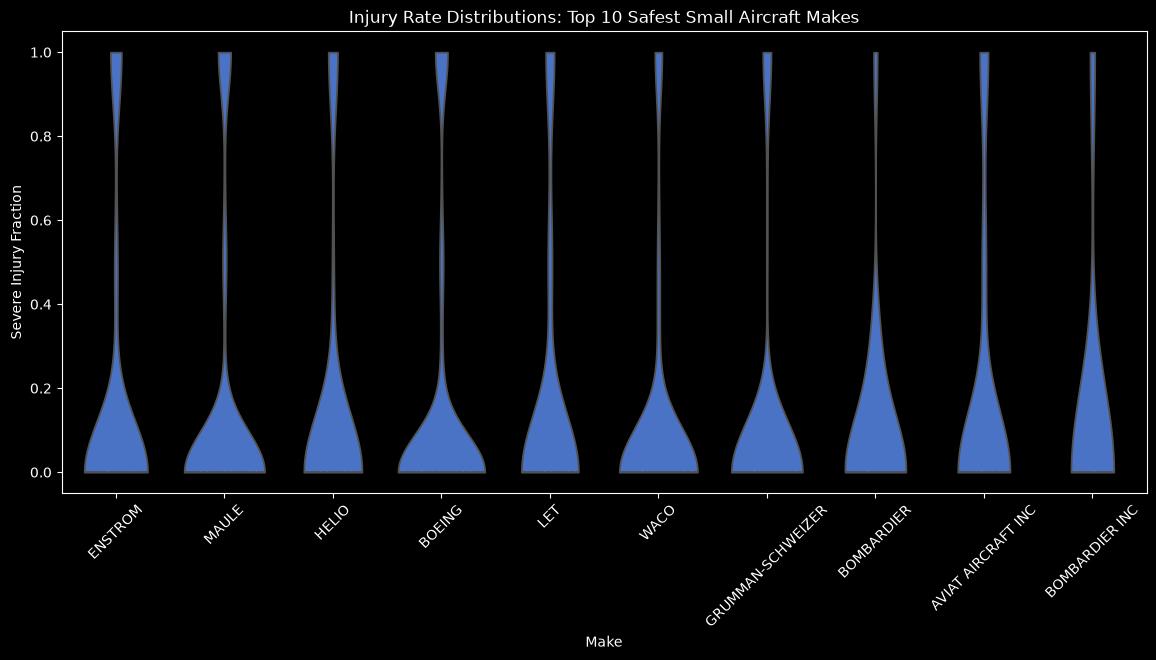

In [19]:
# Identify the 10 makes with lowest mean injury rates in small aircraft
top10_small_makes_list = (
    small_aircraft.groupby('Make')['Severe_Injury_Fraction']
    .mean()
    .nsmallest(10)
    .index
)

# Filter data for only these 10 makes
plot_small_df = small_aircraft[small_aircraft['Make'].isin(top10_small_makes_list)]

# Generate a violin plot
plt.figure(figsize=(14, 6))
sns.violinplot(data=plot_small_df, x='Make', y='Severe_Injury_Fraction', cut=0, inner='quartile')
plt.title('Injury Rate Distributions: Top 10 Safest Small Aircraft Makes')
plt.xticks(rotation=45)
plt.ylabel('Severe Injury Fraction')
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

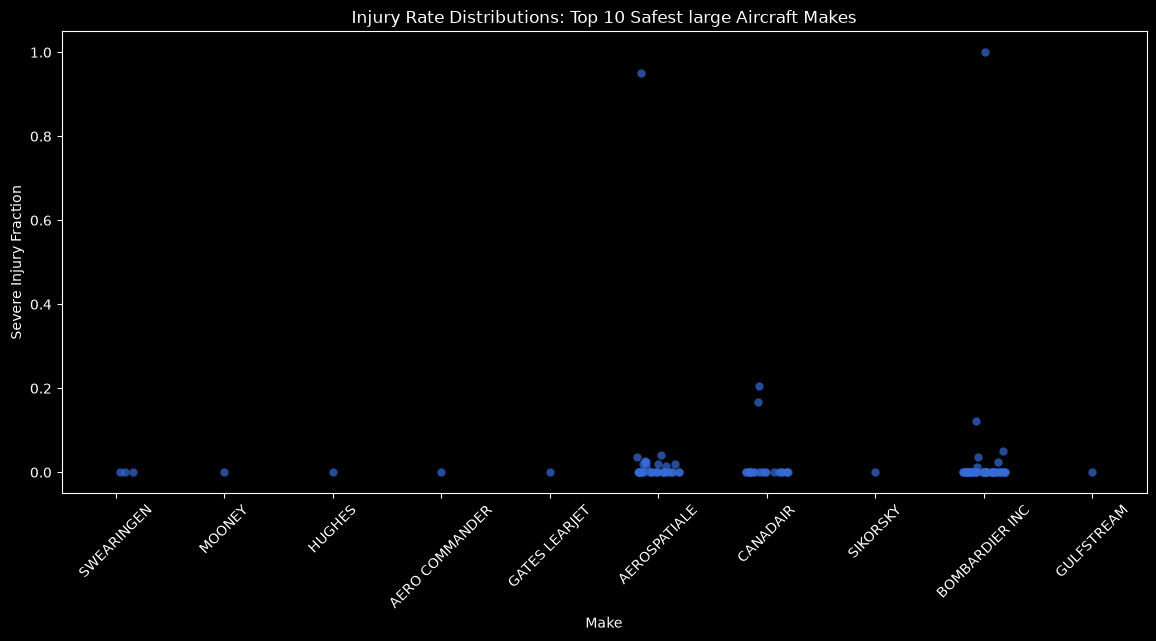

In [21]:
# Identify the 10 makes with lowest mean injury rates in large aircraft
top10_large_makes_list = (
    large_aircraft.groupby('Make')['Severe_Injury_Fraction']
    .mean()
    .nsmallest(10)
    .index
)

# Filter data for only these 10 makes
plot_large_df = large_aircraft[large_aircraft['Make'].isin(top10_large_makes_list)]

# Generate a stripplot plot
plt.figure(figsize=(14, 6))
sns.stripplot(data=plot_large_df, x='Make', y='Severe_Injury_Fraction', jitter=0.2, alpha=0.7, size=6)
plt.title('Injury Rate Distributions: Top 10 Safest large Aircraft Makes')
plt.xticks(rotation=45)
plt.ylabel('Severe Injury Fraction')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [22]:
# Compute mean destruction rate (is_destroyed) per Make
# small
small_destruction = (
    small_aircraft.groupby('Make')['is_destroyed']
    .mean()
    .nsmallest(15)
    .reset_index()
)

In [23]:
# large
large_destruction = (
    large_aircraft.groupby('Make')['is_destroyed']
    .mean()
    .nsmallest(15)
    .reset_index()
)

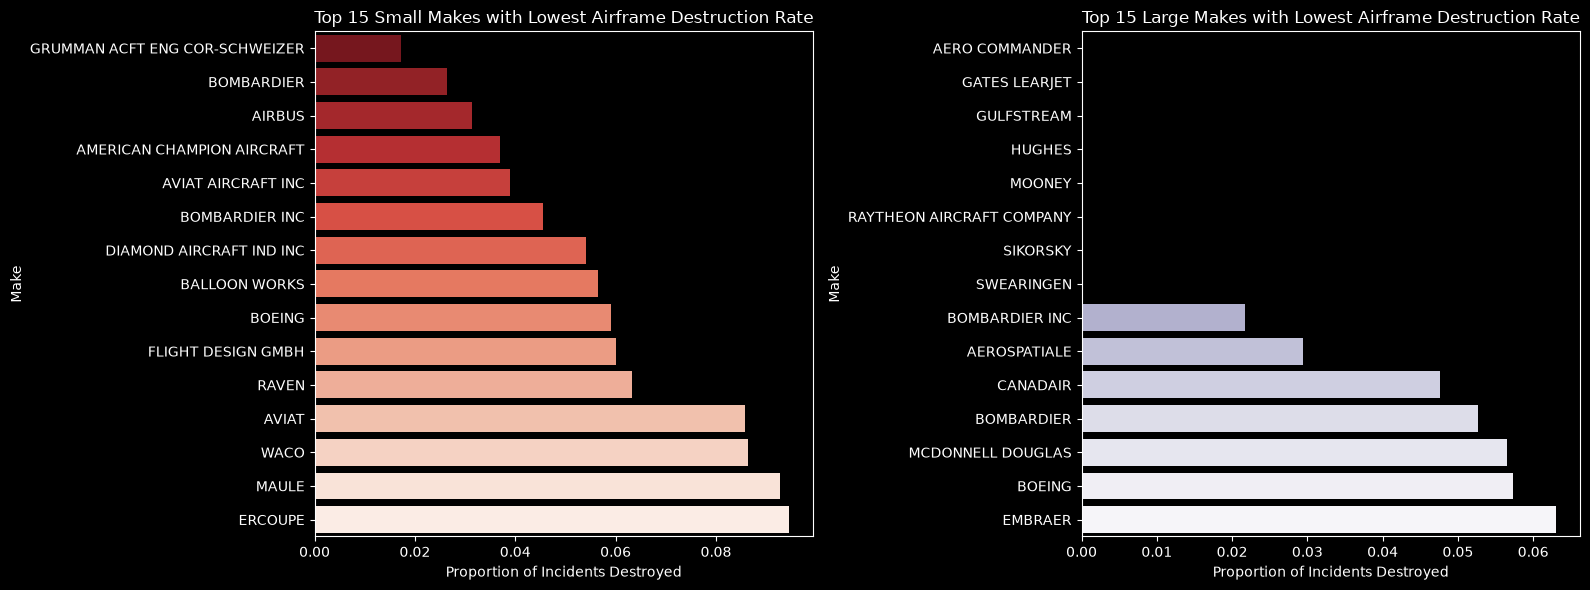

In [24]:
# Plot side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=small_destruction, x='is_destroyed', y='Make', ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 15 Small Makes with Lowest Airframe Destruction Rate')
axes[0].set_xlabel('Proportion of Incidents Destroyed')

sns.barplot(data=large_destruction, x='is_destroyed', y='Make', ax=axes[1], palette='Purples_r')
axes[1].set_title('Top 15 Large Makes with Lowest Airframe Destruction Rate')
axes[1].set_xlabel('Proportion of Incidents Destroyed')

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [45]:
# Count occurrence
large_plane_counts = large_aircraft['Make_Model'].value_counts()

In [46]:
# Filter the valid planes
large_valid_models = large_plane_counts[large_plane_counts >= 10].index

In [48]:
# New subset
df_filtered = large_aircraft[large_aircraft['Make_Model'].isin(large_valid_models)]

In [49]:
# Compute mean injury rates across qualifying models and sort
large_model_summary = (
    df_filtered.groupby('Make_Model')['Severe_Injury_Fraction']
    .agg(['mean', 'count'])
    .sort_values(by='mean')
    .reset_index()
)

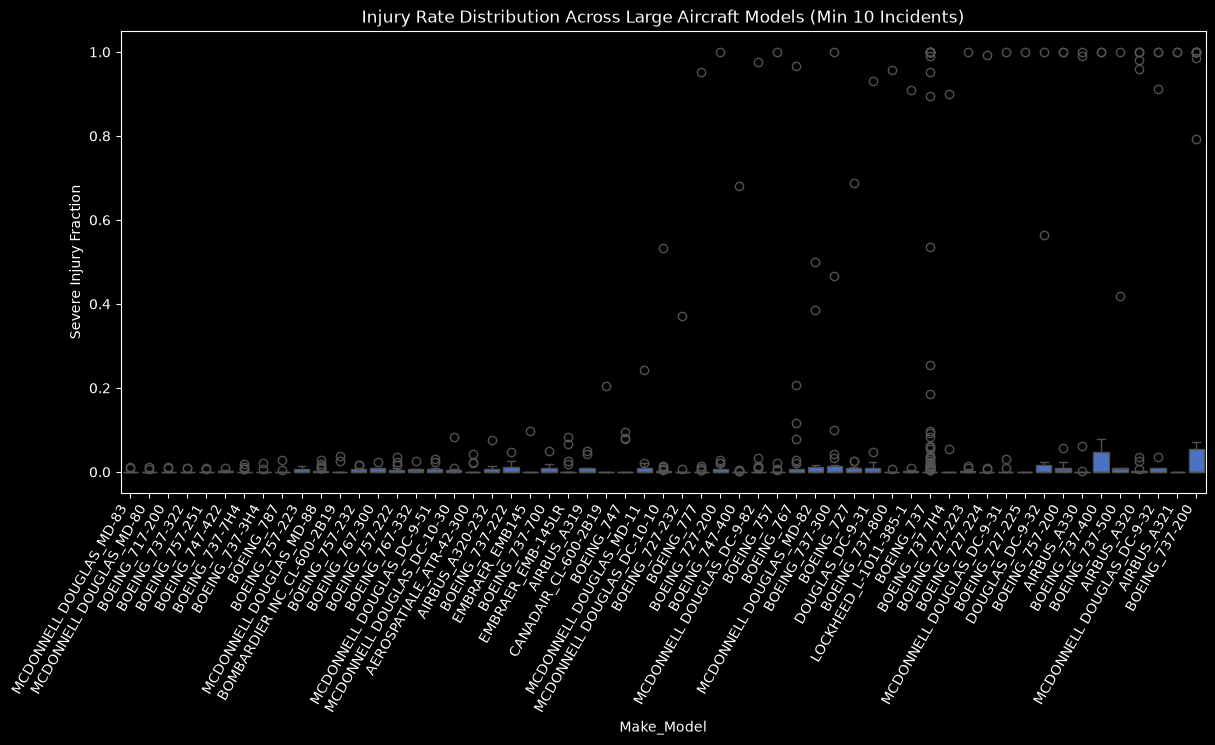

In [50]:
# Distributional plot (boxplot or stripplot) for large plane models
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_filtered, x='Make_Model', y='Severe_Injury_Fraction', order=large_model_summary['Make_Model'])
plt.title('Injury Rate Distribution Across Large Aircraft Models (Min 10 Incidents)')
plt.xticks(rotation=60, ha='right')
plt.ylabel('Severe Injury Fraction')
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [51]:
# Count occurrence
small_plane_count = small_aircraft['Make_Model'].value_counts()

In [52]:
# Filter the valid planes
small_valid_models = small_plane_count[small_plane_count >=10].index

In [56]:
# New subset
df_small_filtered = small_aircraft[small_aircraft['Make_Model'].isin(small_valid_models)]

In [57]:
# Isolate the top 10 models with lowest mean injury fraction
top10_small_models = (
    df_small_filtered.groupby('Make_Model')['Severe_Injury_Fraction']
    .mean()
    .nsmallest(10)
    .index
)

In [58]:
plot_top10_small_models_df = df_small_filtered[df_small_filtered['Make_Model'].isin(top10_small_models)]

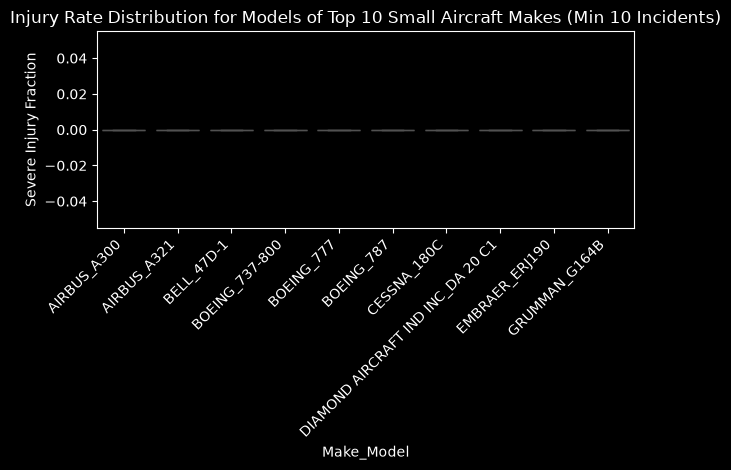

In [61]:
# Distributional plot violinplotplt.figure(figsize=(14, 6))
sns.boxplot(
    data=plot_top10_small_models_df,
    x='Make_Model',
    y='Severe_Injury_Fraction',
    order=top10_small_models
)
plt.title('Injury Rate Distribution for Models of Top 10 Small Aircraft Makes (Min 10 Incidents)')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Severe Injury Fraction')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [62]:
#Factor 1: Weather.Condition

# Weather impact summary (filtering out NaN/Unknown)
weather_clean = df[df['Weather.Condition'].isin(['VMC', 'IMC'])]
weather_summary = (
    weather_clean.groupby('Weather.Condition')[['Severe_Injury_Fraction', 'is_destroyed']]
    .mean()
    .reset_index()
)

In [63]:
# Factor 2: Broad.phase.of.flight

# Phase of flight impact summary (taking primary flight phases)
primary_phases = ['Takeoff', 'Climb', 'Cruise', 'Descent', 'Approach', 'Landing']
phase_clean = df[df['Broad.phase.of.flight'].isin(primary_phases)]
phase_summary = (
    phase_clean.groupby('Broad.phase.of.flight')[['Severe_Injury_Fraction', 'is_destroyed']]
    .mean()
    .reindex(primary_phases)
    .reset_index()
)

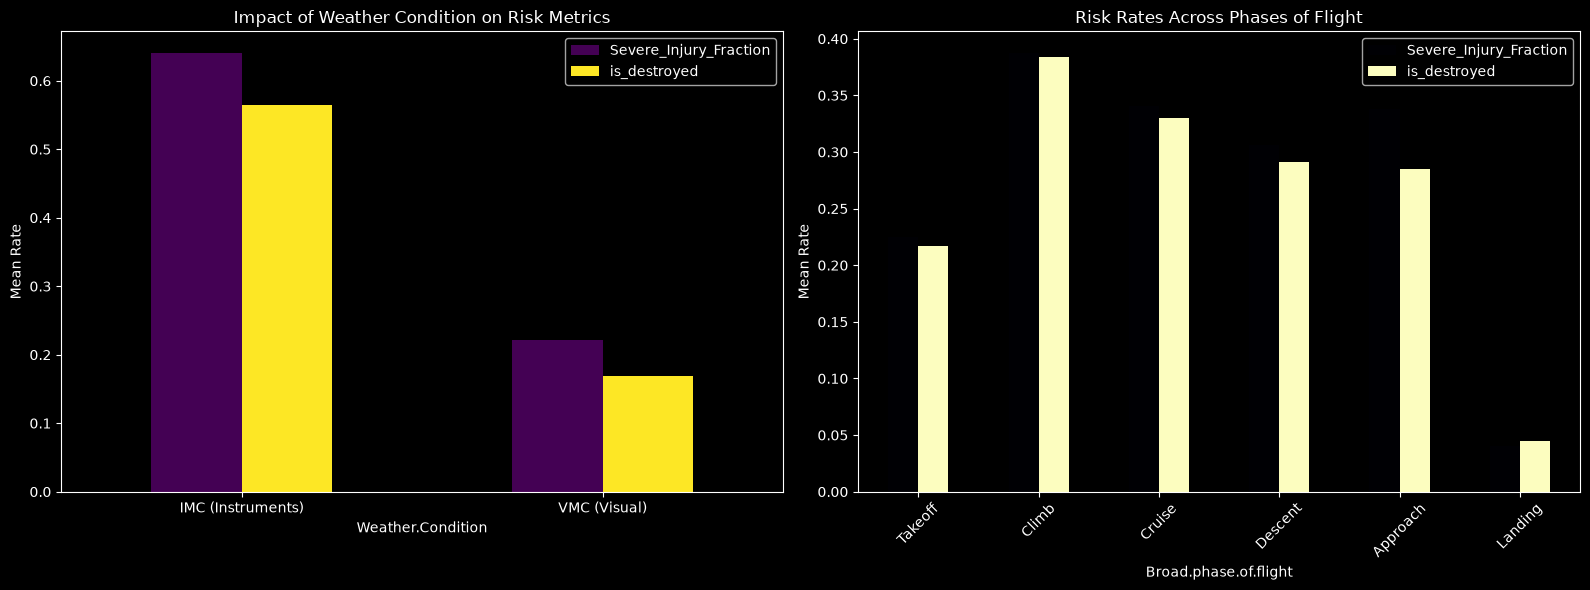

In [65]:
# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Weather comparison
weather_summary.set_index('Weather.Condition').plot(kind='bar', ax=axes[0], colormap='viridis')
axes[0].set_title('Impact of Weather Condition on Risk Metrics')
axes[0].set_ylabel('Mean Rate')
axes[0].set_xticklabels(['IMC (Instruments)', 'VMC (Visual)'], rotation=0)

# Flight phase comparison
phase_summary.set_index('Broad.phase.of.flight').plot(kind='bar', ax=axes[1], colormap='magma')
axes[1].set_title('Risk Rates Across Phases of Flight')
axes[1].set_ylabel('Mean Rate')
axes[1].set_xticklabels(primary_phases, rotation=45)

# Display the output
plt.tight_layout()
plt.show()

## Note
 Instrument Meteorological Conditions (IMC) produce substantially higher severe injury and hull destruction rates compared to clear visual conditions (VMC) due to spatial disorientation and limited reaction time.
## Comparing flight phases
 Landing accounts for high incident volume but lower lethality, whereas cruise or approach accidents often yield higher structural destruction and fatal injury fractions)